# Drop-out experiments
This notebook focuses on the analyses of the six-member models.

# Imports and Load Individual Models

In [1]:
# basic
import os

# see functions.py for a collection of self-written functions for analysing and visualising my models
from functions import *

# cobra & micom
from cobra.io import read_sbml_model
from micom import Community
from micom import load_pickle

# plots
import matplotlib.pyplot as plt
import seaborn as sns

# Load SBML Models - individuals

In [49]:
models_path = "../Models/02_afterCuration/"
models = {}
for model_name in (f for f in os.listdir(models_path) if f.endswith(".xml")):
    model = read_sbml_model(f"{models_path}/{model_name}")
    model.solver = "cplex"
    name = str(model_name[:3])
    models[name] = model

models = {key: models[key] for key in sorted(models.keys())}  # sorts the dictionary alphabetically
AA1, AA2, AA3, AA4, AA5, AA6, AA7 = [models[f"AA{i}"] for i in range(1, 8)]

# Functions

In [2]:
def e_to_m(medium):
    if isinstance(medium, dict):
        # Convert reaction IDs ending in '_e' to '_m'
        medium_dict = {k.removesuffix('_e') + '_m' if k.endswith('_e') else k: v for k, v in medium.items()}
        return medium_dict

    elif isinstance(medium, pd.DataFrame):
        # Convert DataFrame to a dict with converted reaction IDs
        medium_dict = {rxn.removesuffix('_e') + '_m' if rxn.endswith('_e') else rxn: bound for rxn, bound in
                       zip(medium["reaction"], medium["bound"])}
        return medium_dict

    else:
        return "Medium is wrong data type"

In [3]:
# change the amount of decimals that are shown in the plots
def custom_format(x):
    if round(x, 1) == 0:
        return "0"  # no decimals for 0
    else:
        return f"{x:.1f}"  # 1 decimals otherwise

In [4]:
def heatmap_growth_dropouts(models, medium, save=False):
    growth_data = {}

    for name, syncom in models.items():
        _, growth = community_pfba(syncom, medium)
        if growth is not None:
            growth_data[name] = growth

    growth_df = pd.DataFrame(growth_data).transpose()

    epsilon = 1e-6
    growth_df = growth_df.applymap(lambda x: 0 if abs(x) < epsilon else x)

    # --- Rename strains (columns) ---
    strain_map = {
        "AA1": "Sma",
        "AA2": "Bpi",
        "AA3": "Cpu",
        "AA4": "Elu",
        "AA5": "Cin",
        "AA6": "Hro",
        "AA7": "Ppu"
    }
    growth_df = growth_df.rename(columns=strain_map)

    # --- Rename communities (rows) ---
    community_map = {
        "C7_Community": "C7",
        "S1": "C7-Sma",
        "S2": "C7-Bpi",
        "S3": "C7-Cpu",
        "S4": "C7-Elu",
        "S5": "C7-Cin",
        "S6": "C7-Hro",
        "S7": "C7-Ppu"
    }
    growth_df = growth_df.rename(index=community_map)

    # Desired plotting order
    strain_order = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
    community_order = ["C7-Sma", "C7-Bpi", "C7-Cpu", "C7-Elu", "C7-Cin", "C7-Hro", "C7-Ppu", "C7"]

    plt.figure(figsize=(10, 6))

    growth_df = growth_df.apply(pd.to_numeric, errors='coerce')
    annot_str = growth_df.applymap(custom_format)
    annot_data = annot_str.loc[community_order, strain_order].T

    ax = sns.heatmap(
        growth_df.loc[community_order, strain_order].T,
        fmt="",
        annot=annot_data,
        cmap="Reds",
        cbar_kws={'label': 'growth rate [mmol/(gDW h)]'}
    )

    ax.set_xticklabels(community_order, rotation=45, ha="right")
    ax.set_yticklabels(strain_order, rotation=0)

    # Make NaN background white
    ax.set_facecolor("white")

    plt.title(f"Growth per strain across community model variants (including full community)\non maize root medium")
    plt.xlabel("Community variant")
    plt.ylabel("Strains")
    plt.tight_layout()

    if save:
        file_name = f"drop_outs_growth_mrm.svg"
        plt.savefig(f"../Figures/{file_name}", format="svg", bbox_inches="tight")
    plt.show()

    return growth_df

# Medium

In [7]:
m9 = pd.read_csv("../Datasets/Medium/medium_M9.csv", sep=";")
m9_rxn = list(m9["reaction"])

maize_root_medium = pd.read_csv("../Datasets/Medium/MRM_whole.csv", sep=";", quotechar='"')

ecoplate = pd.read_csv("../Datasets/Medium/medium_ecoplate_carbon.csv", sep=";", quotechar='"')
ecoplate_rxns = [safe_parse(x) for x in ecoplate["reaction"]]

#ecoplate_short = pd.read_csv("../Datasets/Medium/medium_ecoplate_carbon_shortened.csv", sep=";", quotechar='"')
#ecoplate_rxns_short = [safe_parse(x) for x in ecoplate_short["reaction"]]

# Create C7 Community Model with MICOM

In [ ]:
taxonomy = pd.read_csv("../Datasets/Taxonomy_community_micom.csv", sep=";")

syncom = Community(taxonomy.iloc[:, :-1], name="synthetic seven member bacterial community", id="C7", solver="cplex")

# change lower bound of Exchange reactions (EX between bacteria and medium)
for rxn in syncom.reactions.query("^EX_"):
    rxn.lower_bound = -1000

# Load or Create Drop-Out Communities
From our C7 community we want to exclude one bacterium at a time making it a C6 community.

In [9]:
# Load Models - Drop outs
models_path = "../Models/03_Drop_outs"
drops = {}
for model_name in (f for f in os.listdir(models_path) if f.endswith(".pickle")):
    model = load_pickle(f"{models_path}/{model_name}")
    model.solver = "cplex"
    name = str(model_name[:2])
    drops[name] = model

drops = {key: drops[key] for key in sorted(drops.keys())}  # sorts the dictionary alphabetically
S1, S2, S3, S4, S5, S6, S7 = [drops[f"S{i}"] for i in range(1, 8)]

In [ ]:
"""
The code below builds Drop-Out models from the individual models. As this process can be time-consuming, we have saved the models as .pickles that can be loaded instead of newly created every time this notebook is executed. So you can skip this step and use the models you loaded above.

ATTENTION: "normal" saving with write_sbml_model doesnt work for MICOM Community model
    --> We need to save them as pickles
    --> see: https: // resendislab.github.io / micom / community.html

syncoms = {}

for i in range(len(taxonomy)):
    cut_tax = taxonomy.drop(index=taxonomy.index[i])
    name = f"syncom_drop{i + 1}"

    com = Community(
        cut_tax.iloc[:, :-1],
        name="synthetic six member bacterial community",
        id=name,
        solver="cplex")

    # Set EX reaction bounds for this syncom
    for rxn in com.reactions.query("^EX_"):
        rxn.lower_bound = -1000  # make exchange freely available

    syncoms[name] = com

S1, S2, S3, S4, S5, S6, S7 = [syncoms[f"syncom_drop{i + 1}"] for i in range(7)]
all_models = {**syncoms, 'C7_Community': syncom}


# save all drop-out models as pickles
for i, model in enumerate(syncoms.values(), start=1):
    path = f"../Models/03_Drop_outs/S{i}.pickle"
    model.to_pickle(path)
"""

In [10]:
all_models = {**drops, 'C7_Community': syncom}

# Growth on maize root medium

In [9]:
# Growth for all drop-out syncoms
for model in all_models.values():
    print(test_medium(model, maize_root_medium))

model
AA2    21.003812
AA3    12.153178
AA4    15.051207
AA5    13.083090
AA6    14.886655
AA7    15.521723
Name: Growth, dtype: float64
model
AA1    17.182530
AA3    14.939989
AA4    15.219824
AA5    15.347434
AA6    15.320994
AA7    15.411271
Name: Growth, dtype: float64
model
AA1    17.352790
AA2    18.760078
AA4    17.198780
AA5    17.768730
AA6    15.896650
AA7    17.989189
Name: Growth, dtype: float64
model
AA1    19.136741
AA2    18.943171
AA3    10.967272
AA5    16.962475
AA6    17.802758
AA7     8.572808
Name: Growth, dtype: float64
model
AA1    17.280142
AA2    17.786583
AA3    12.861582
AA4    15.105542
AA6    15.221181
AA7    15.470521
Name: Growth, dtype: float64
model
AA1    17.798650
AA2    18.022046
AA3    13.569908
AA4    14.502898
AA5    13.897995
AA7    15.132529
Name: Growth, dtype: float64
model
AA1    15.097043
AA2    15.089361
AA3    15.097043
AA4    15.097043
AA5    15.097043
AA6    15.097043
Name: Growth, dtype: float64
model
AA1    17.872014
AA2    18.812332
A

/tmp/ipykernel_62173/665802510.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  growth_df = growth_df.applymap(lambda x: 0 if abs(x) < epsilon else x)
/tmp/ipykernel_62173/665802510.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_str = growth_df.applymap(custom_format)


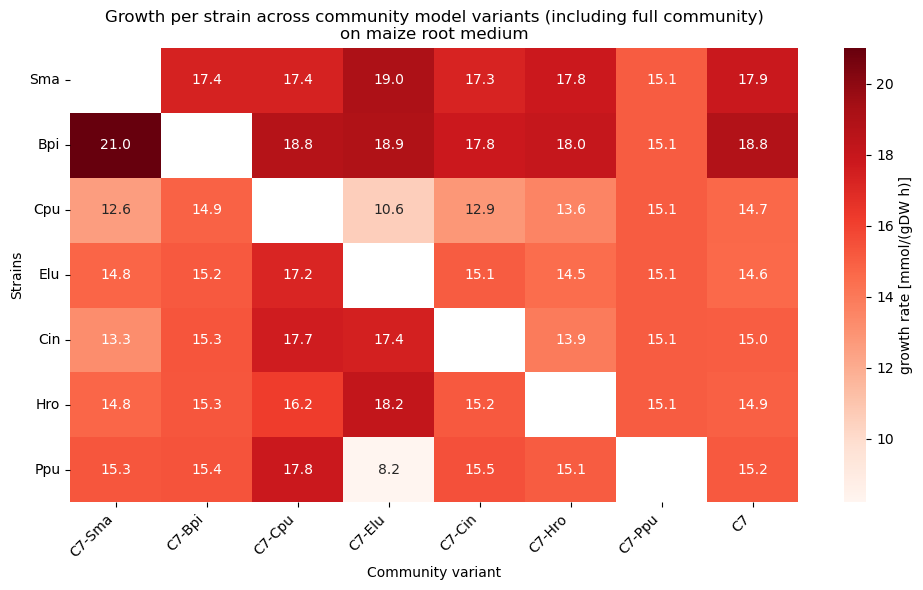

In [17]:
growth_mrm_df = heatmap_growth_dropouts(all_models, maize_root_medium)

# PCA

In [12]:
community_map = { "C7_Community": "C7", "S1": "C7-Sma", "S2": "C7-Bpi", "S3": "C7-Cpu", "S4": "C7-Elu", "S5": "C7-Cin", "S6": "C7-Hro", "S7": "C7-Ppu" }

## PCA - Growth rates

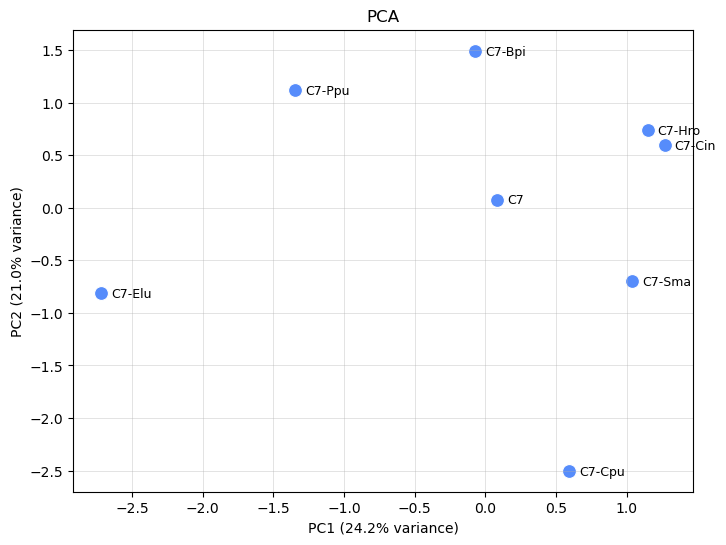

In [18]:
pca(growth_mrm_df)

## PCA - All fluxes

In [27]:
flux_tables = {}

for model_name, model in all_models.items():
    flux_series = get_pfba_fluxes(model, maize_root_medium)
    flux_tables[model_name] = flux_series

# Combine into one dataframe
all_fluxes = pd.concat(flux_tables, axis=1)

# Replace missing reactions with zero
all_fluxes = all_fluxes.fillna(0)

# set model names as columns (instead of MultiIndex)
all_fluxes.columns = all_fluxes.columns.get_level_values(0)

In [28]:
all_fluxes = all_fluxes.rename(columns=community_map)

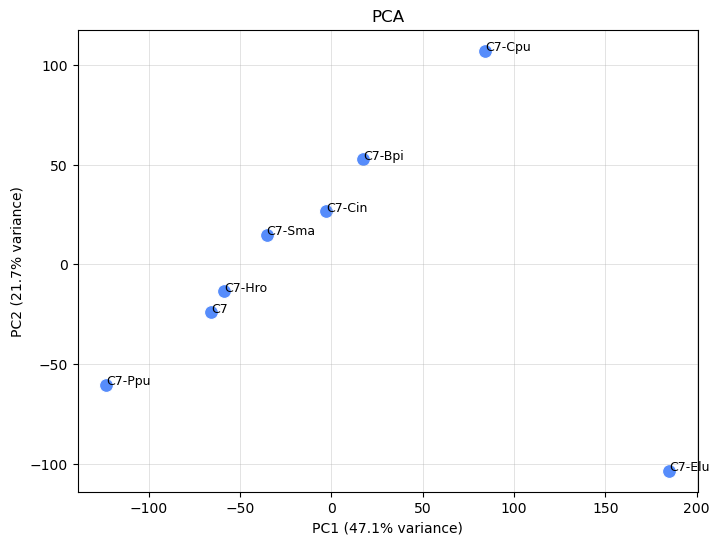

In [29]:
pca(all_fluxes.T)

## PCA - Exchange reactions

In [13]:
# Prepare an empty dict to store fluxes
flux_ex_tables = {}

# Loop over models and media
for model_name, model in all_models.items():
    flux_ex_series = get_pfba_fluxes(model, maize_root_medium)

    # filter series to only have Exchange reactions and not all reactions
    # because we have a community, this includes exchanges between the models and the shared compartment and the uptake/secretion of the environment with the whole community model
    flux_ex_series = flux_ex_series[flux_ex_series.index.str.startswith("EX")]

    flux_ex_tables[model_name] = flux_ex_series

exchange_fluxes = pd.concat(flux_ex_tables, axis=1).fillna(0)
exchange_fluxes.columns = exchange_fluxes.columns.get_level_values(0)
exchange_fluxes = exchange_fluxes.rename(columns=community_map)

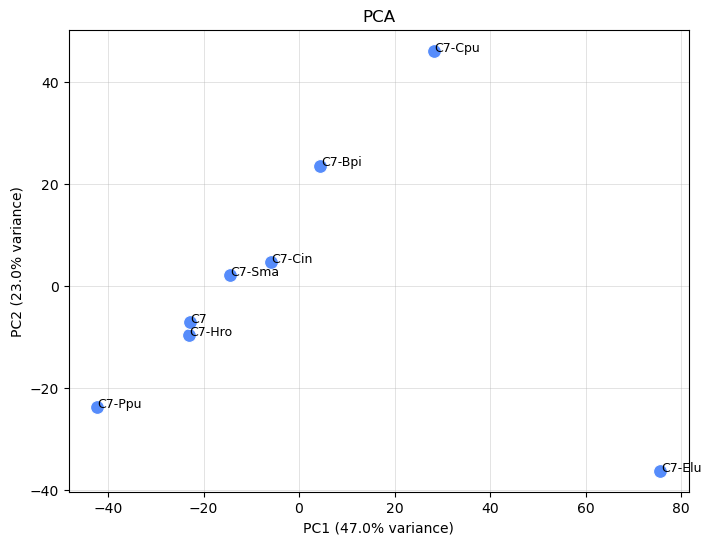

In [14]:
pca(exchange_fluxes.T,save_path="../Figures/PCA_EX_C6.svg")

# Substrate Utilisation (BIOLOG Ecoplate)
def create_medium(carbon_list, minimal_list, model_dict, medium_uptake_bound, carbon_only=False):

In [40]:
metab_axis = ["Phenylethylamine", "Putrescine", "Glycyl-glutamic acid", "L-arginine", "Asparagine", "Phenylalanine",
                  "Serine", "Threonine", "Glycerol-phosphate", "Cellobiose", "Mannitol", "Xylose",
                  "Glucose-1-phosphate", "Acetyl-glucosamine", "4-Hydroxy benzoic acid", "Galacturonic acid",
                  "Malic acid", "2-Hydroxy-benzoic acid", "Lactose", "Butyric acid", "Water (Control)"]

[11/07/26 22:05:59] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885723;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885724;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:02] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885729;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885730;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:05] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885735;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885736;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:09] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885741;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885742;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:11] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885747;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885748;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:14] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885753;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885754;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:18] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885759;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885760;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

[11/07/26 22:06:21] WARNING  There does not seem to be any carbon source in your medium. Please    ]8;id=15885765;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py\community.py]8;;\:]8;id=15885766;file:///home/schoenherrl/miniconda3/envs/c7/lib/python3.10/site-packages/micom/community.py#667\667]8;;\
                             double-check your medium IDs.                                                         

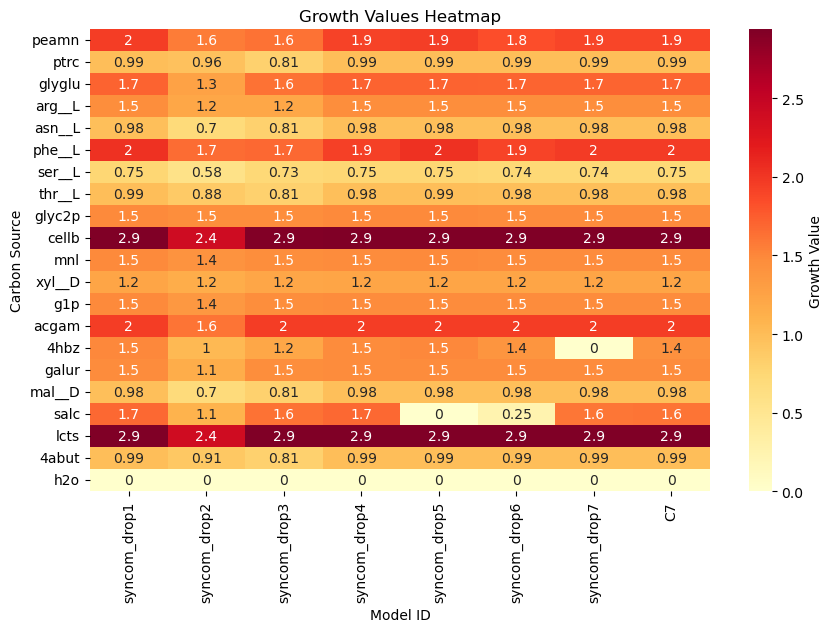

In [41]:
ecoplate_df = create_medium(ecoplate_rxns, m9_rxn, all_models, 10, carbon_only=True, average="yes")
# takes around 9min (up to 20min on slower machines)

In [45]:
# for nicer visualisation: better labels
ecoplate_df.index = metab_axis
ecoplate_df.index.name = "Substrate"
ecoplate_df.columns = ["C7-Sma", "C7-Bpi", "C7-Cpu", "C7-Elu", "C7-Cin", "C7-Hro", "C7-Ppu", "C7"]
ecoplate_df = ecoplate_df.fillna(0)

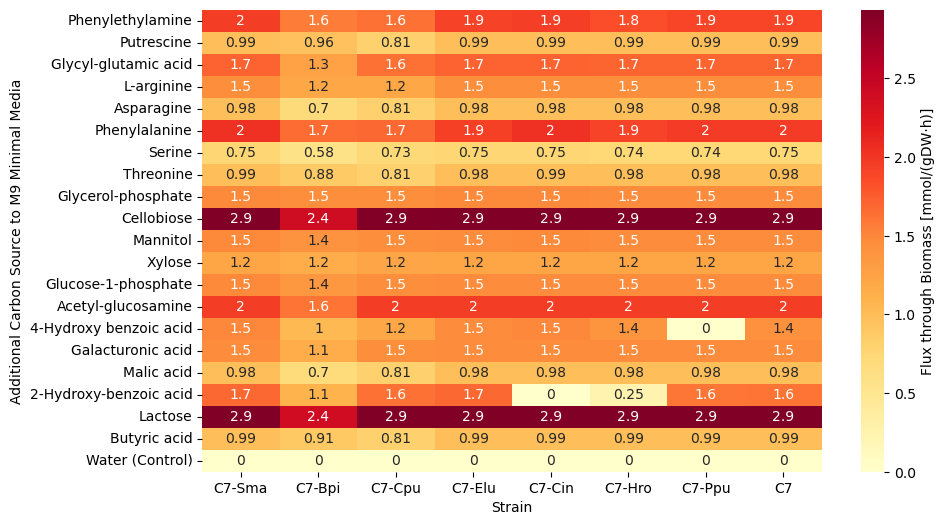

In [43]:

# Create a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(ecoplate_df, annot=True, cmap="YlOrRd", cbar_kws={'label': 'Flux through Biomass [mmol/(gDW·h)]'})
# plt.title("")
plt.xlabel("Strain")
#plt.yticks(ticks=np.arange(len(metab_axis)), labels=metab_axis)
plt.ylabel("Additional Carbon Source to M9 Minimal Media")
#plt.savefig("../Figures/ecoplate.svg", format="svg", bbox_inches="tight")
plt.show()

In [46]:
# Export as csv
#ecoplate_df.to_csv("../Datasets/in_silico_data/Ecoplate_C6_S_test.csv")

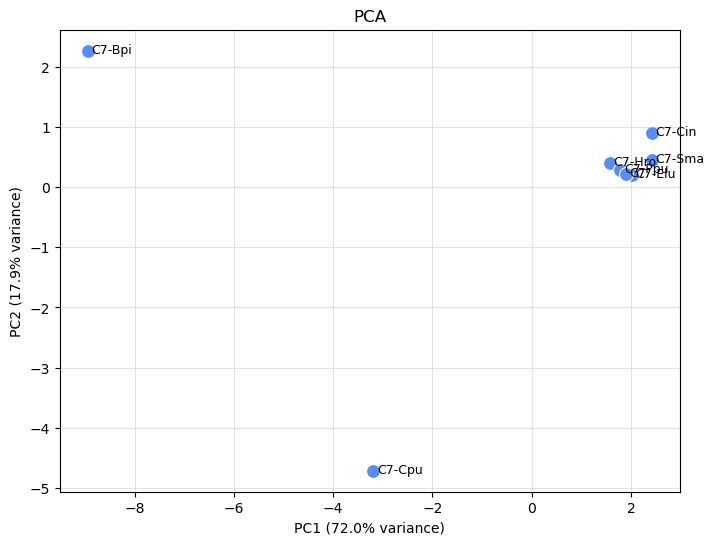

In [47]:
pca(ecoplate_df.T)

# Uptakes and Secretions

## One community within

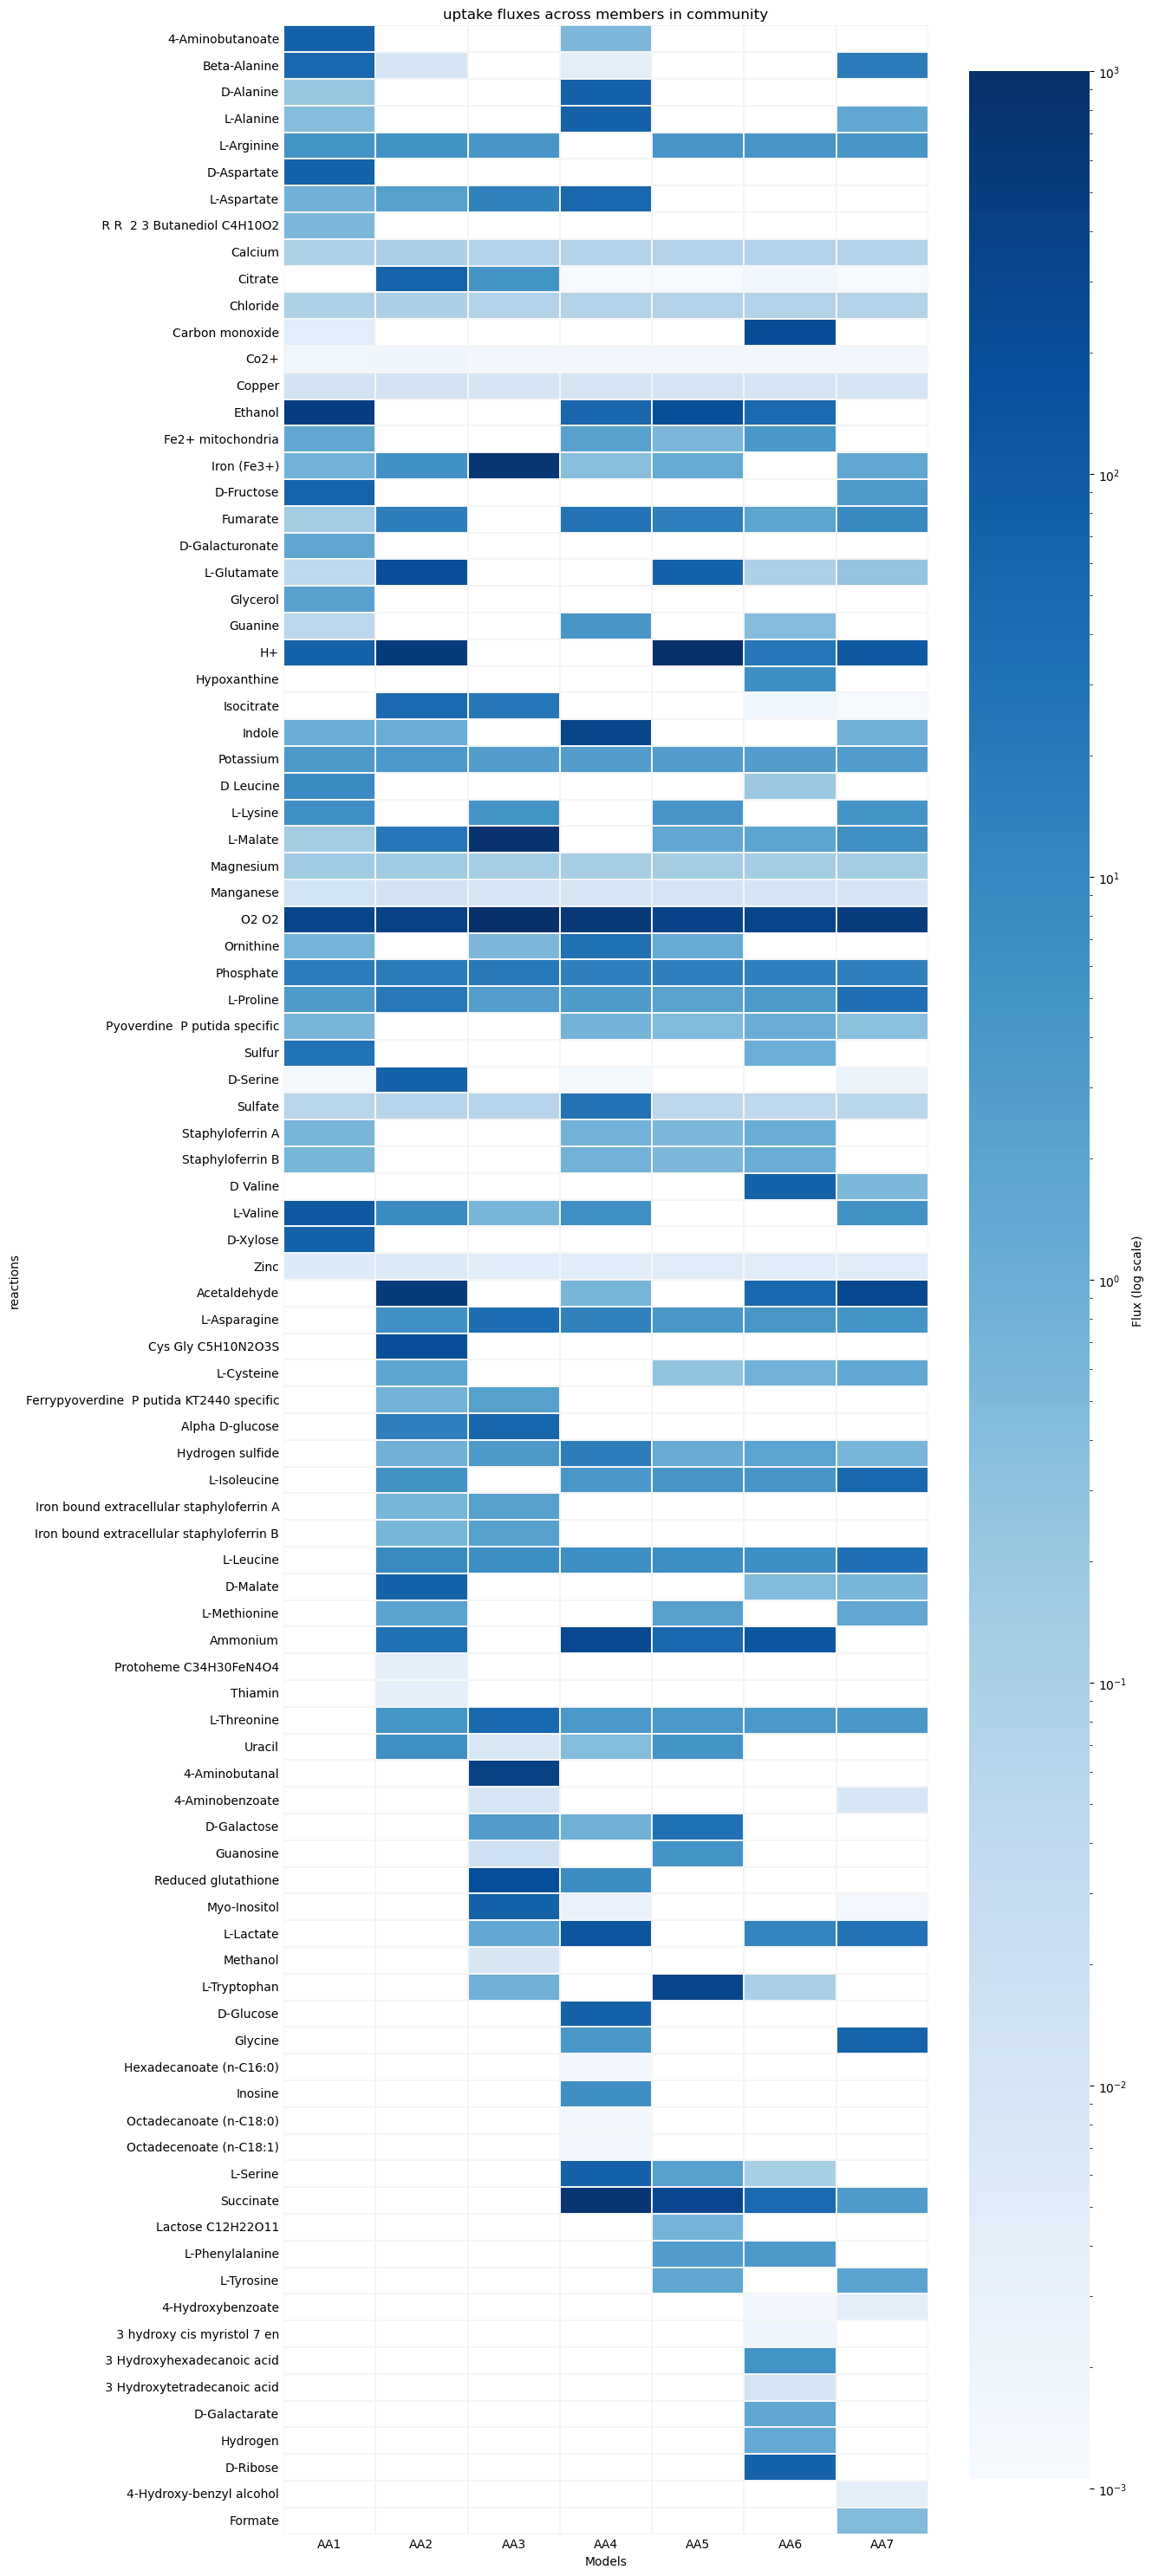

,AA1,AA2,AA3,AA4,AA5,AA6,AA7
4-Aminobutanoate,69.433705,NaN,NaN,0.566705,NaN,NaN,NaN
Beta-Alanine,52.334389,0.010402,NaN,0.004410,NaN,NaN,17.651175
D-Alanine,0.220549,NaN,NaN,69.988425,NaN,NaN,NaN
L-Alanine,0.398013,NaN,NaN,68.016911,NaN,NaN,1.585507
L-Arginine,5.286375,5.564537,4.34106,NaN,4.443408,4.418785,4.435656
...,...,...,...,...,...,...,...
D-Galactarate,NaN,NaN,NaN,NaN,NaN,1.636429,NaN
Hydrogen,NaN,NaN,NaN,NaN,NaN,1.355859,NaN
D-Ribose,NaN,NaN,NaN,NaN,NaN,70.000421,NaN
4-Hydroxy-benzyl alcohol,NaN,NaN,NaN,NaN,NaN,NaN,0.004142


In [50]:
heatmap_fluxes_withinCommunity(syncom, models, maize_root_medium, "uptake")

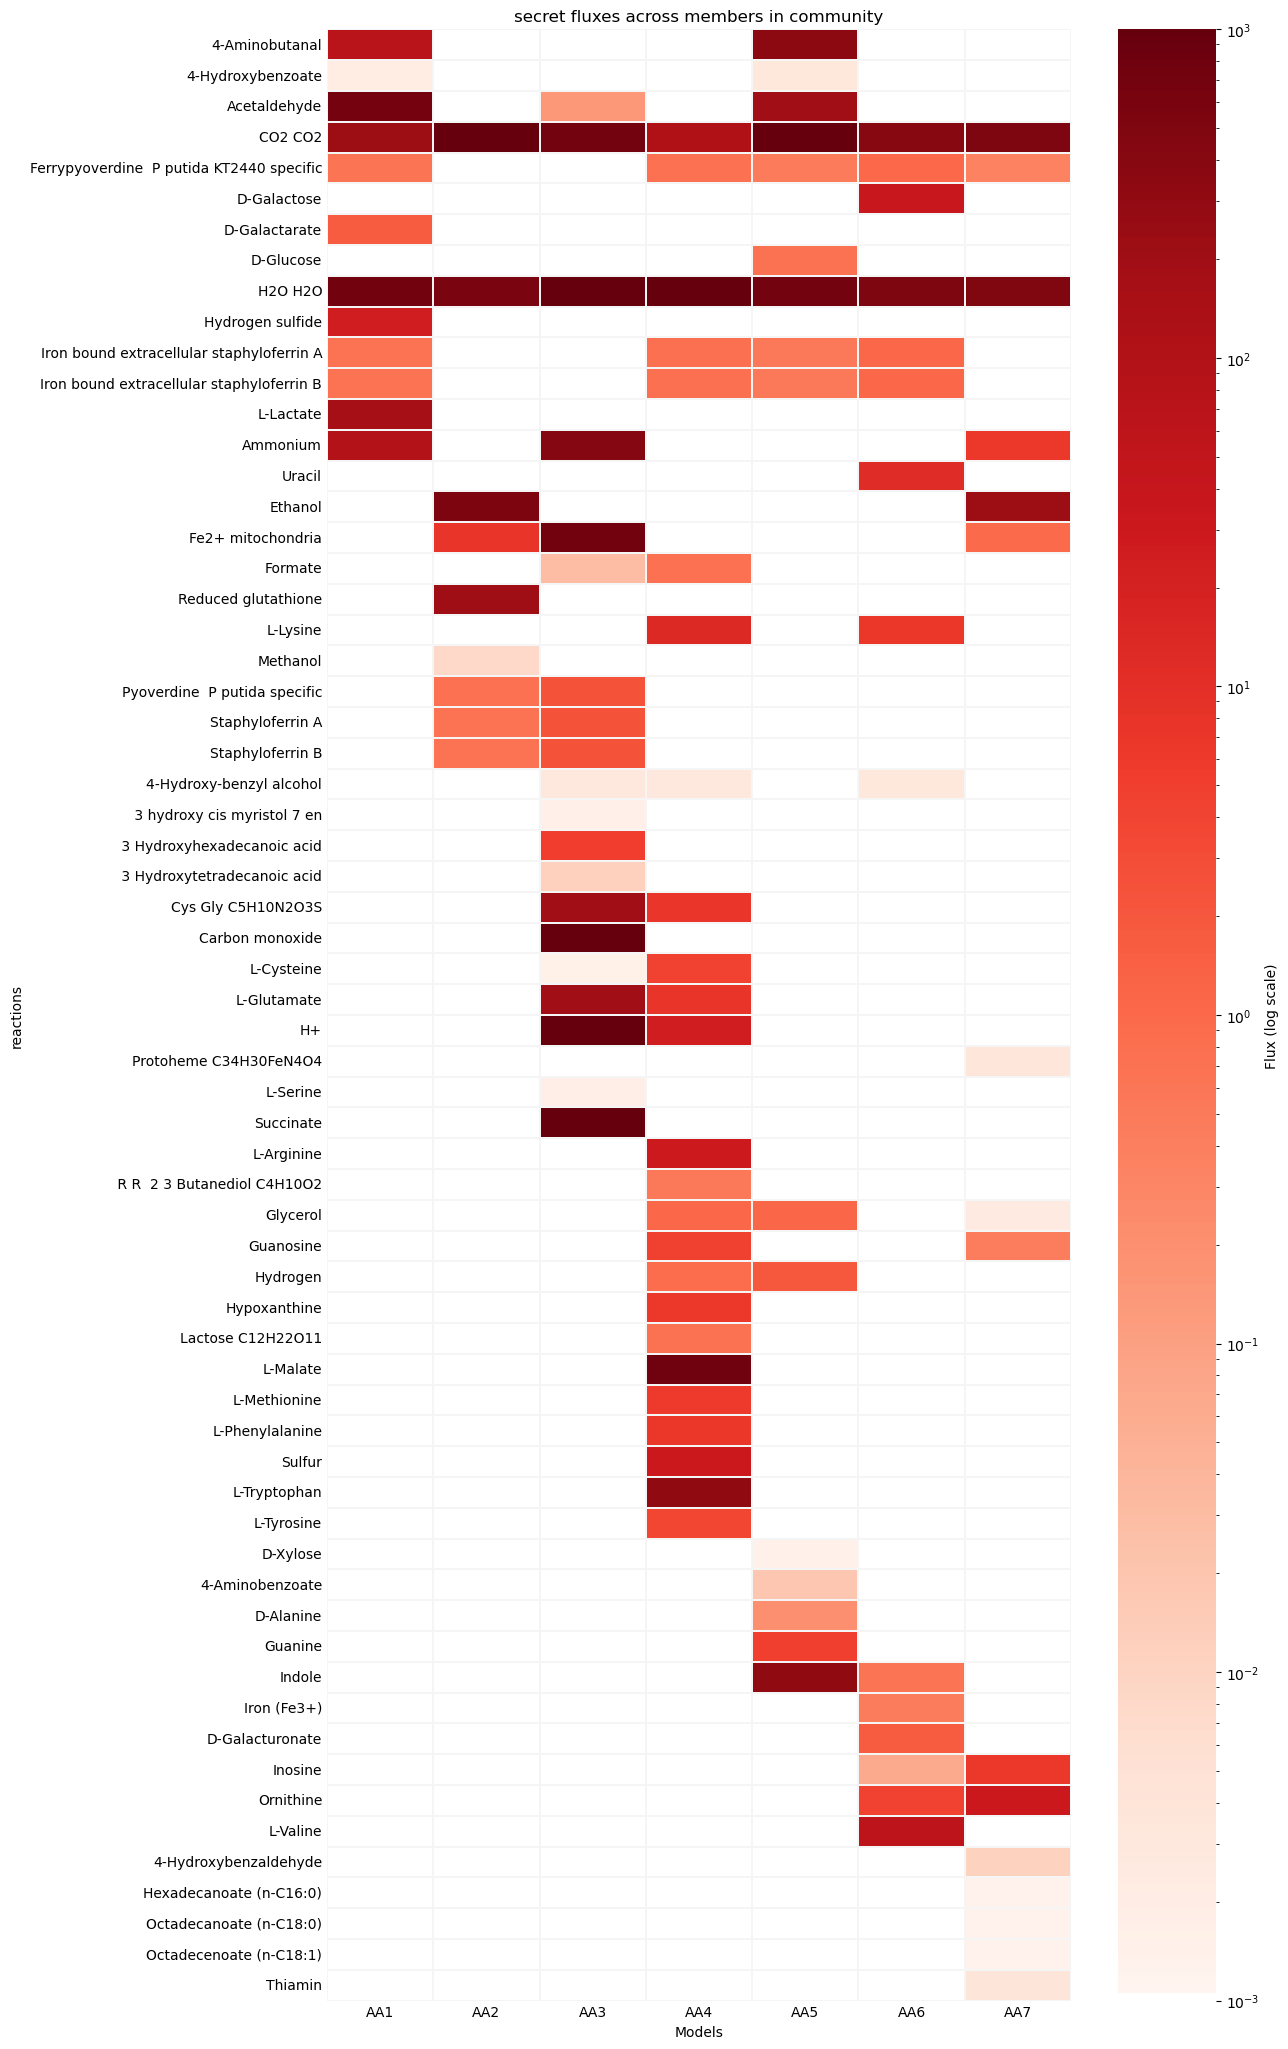

,AA1,AA2,AA3,AA4,AA5,AA6,AA7
4-Aminobutanal,69.433716,NaN,NaN,NaN,342.815370,NaN,NaN
4-Hydroxybenzoate,0.002227,NaN,NaN,NaN,0.003391,NaN,NaN
Acetaldehyde,667.852165,NaN,0.150024,NaN,196.432181,NaN,NaN
CO2 CO2,223.793567,999.991463,688.362277,111.097648,982.746289,398.497627,511.283217
Ferrypyoverdine P putida KT2440 specific,0.616401,NaN,NaN,0.741564,0.478593,1.033875,0.343575
...,...,...,...,...,...,...,...
4-Hydroxybenzaldehyde,NaN,NaN,NaN,NaN,NaN,NaN,0.011282
Hexadecanoate (n-C16:0),NaN,NaN,NaN,NaN,NaN,NaN,0.001274
Octadecanoate (n-C18:0),NaN,NaN,NaN,NaN,NaN,NaN,0.001269
Octadecenoate (n-C18:1),NaN,NaN,NaN,NaN,NaN,NaN,0.001251


In [51]:
heatmap_fluxes_withinCommunity(syncom, models, maize_root_medium, "secret")

## Across all drop out communities

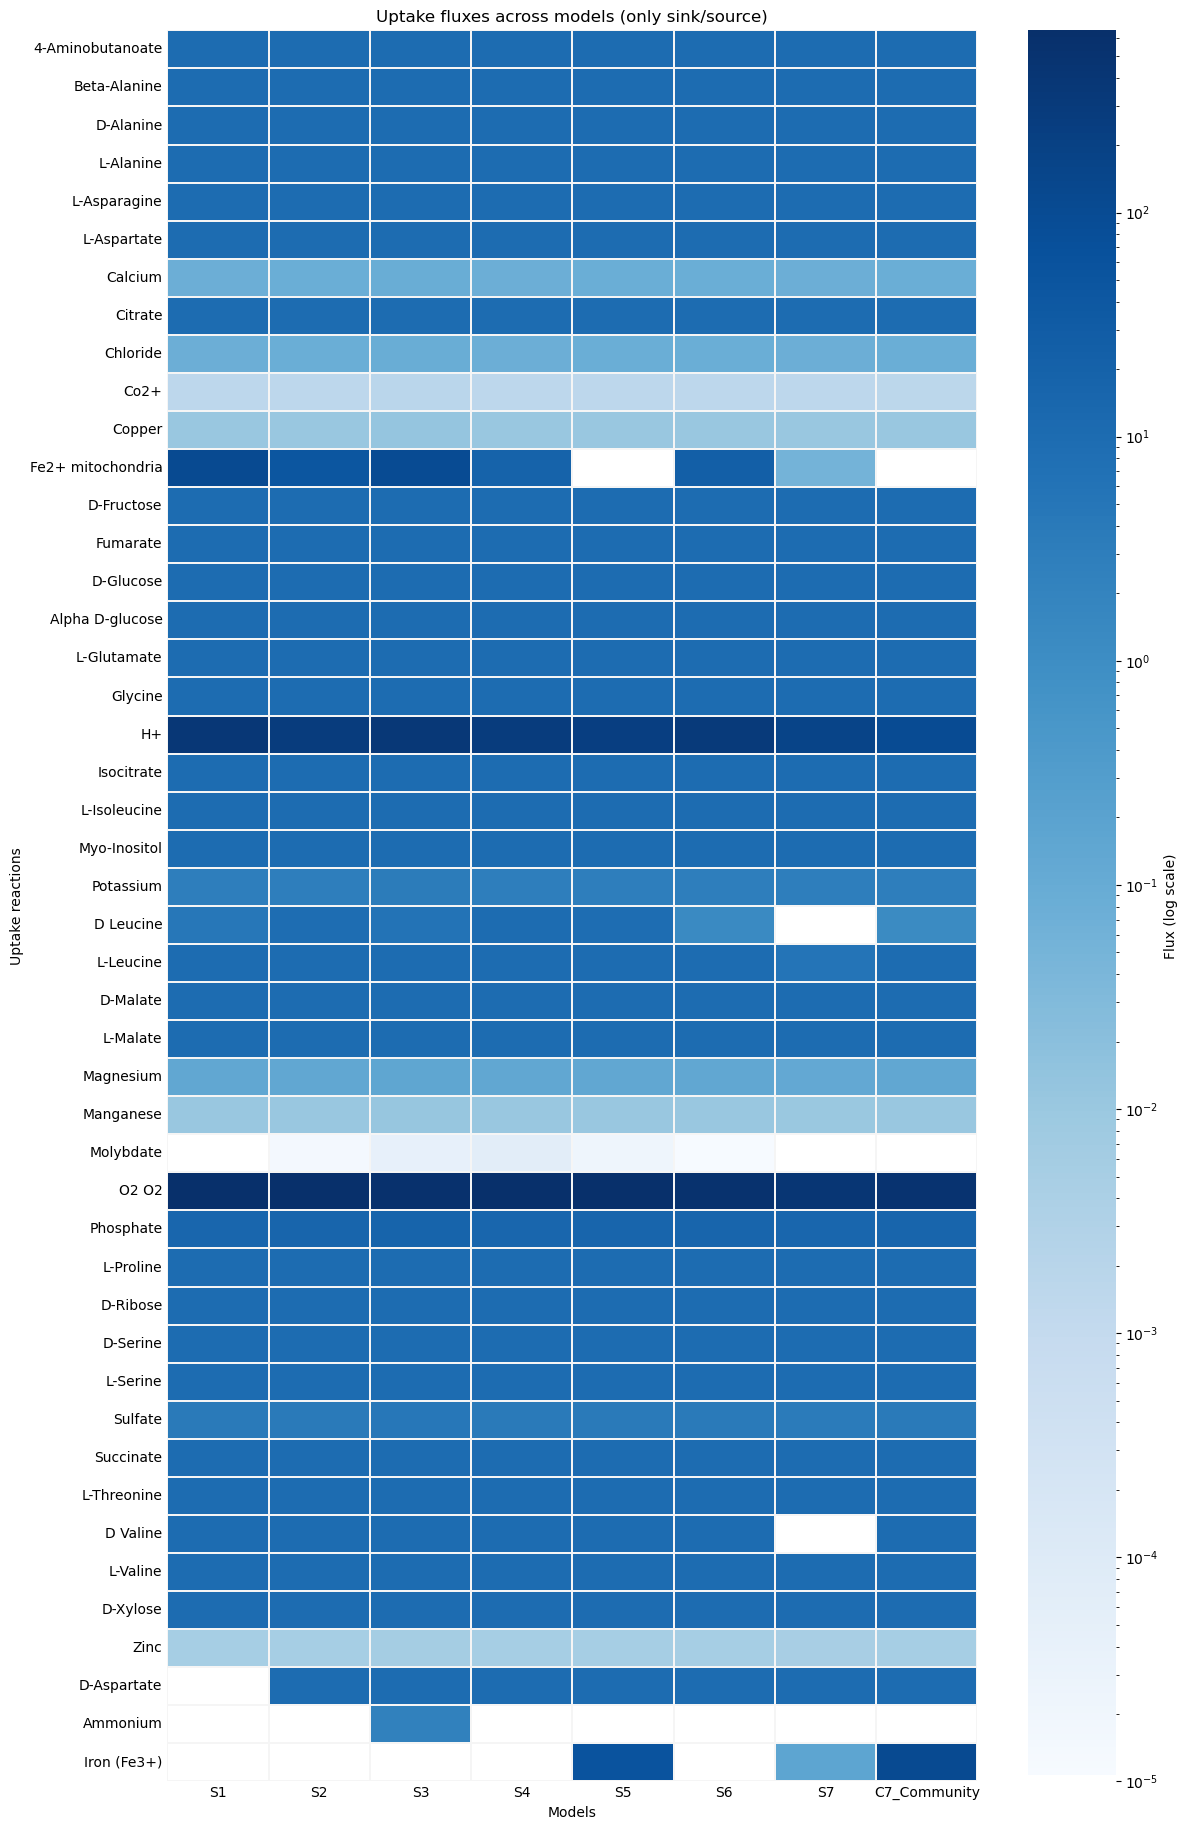

In [52]:
uptake_df_alldrops = uptake_secret_heatmap(all_models, "uptake", maize_root_medium, c7_all_ex="no")

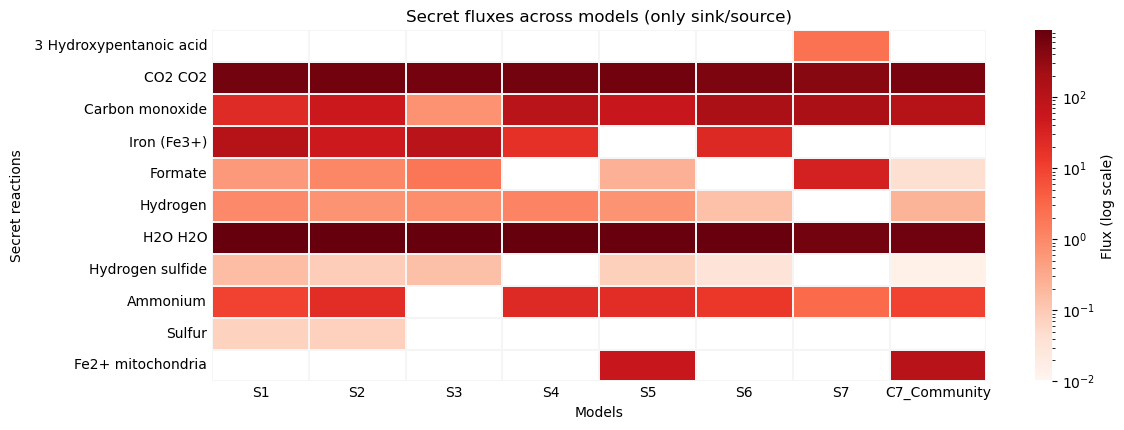

In [53]:
secret_df_alldrops = uptake_secret_heatmap(all_models, "secret", maize_root_medium, c7_all_ex="no", vmin=0.01)

# Community fractions
The fraction is a parameter in MICOMs pFBA function; it simulates how egotistical a strain can be or if the whole community is favoured more. For C7-Ppu (in the Notebook also named S7) we saw previously that all strains have the same growth rate. As I am using one fixed fraction, I wanted to check if the fraction parameter makes a difference for C7-Ppu also in comparison with our normal syncom, the C7. For the C7, only a fraction of 1 yields different growth rates for the members. In C7-Ppu apparently there is not one strain that outcompetes the others.

/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(strain_codes):
/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(strain_codes):
/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(stra

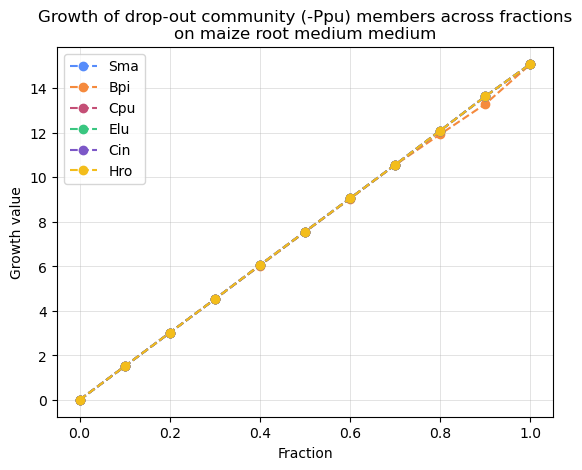

In [54]:
test_fractions_community(S7, maize_root_medium, drop_out="Ppu", medium_name="maize root medium")

/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(strain_codes):
/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(strain_codes):
/home/schoenherrl/Dokumente Lisa/C7/Scripts/functions.py:1015: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for i, code in enumerate(stra

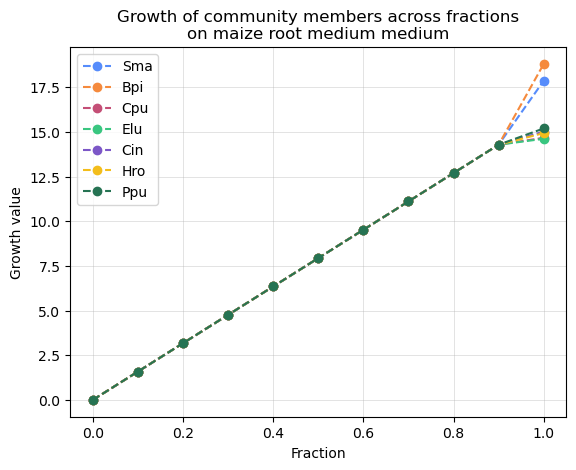

In [55]:
test_fractions_community(syncom, maize_root_medium, drop_out=None, medium_name="maize root medium")